In [4]:
import sys
from pathlib import Path

# Racine du projet
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))


In [5]:
from src.pipeline.preprocess import fetch_data
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [6]:
query="""
SELECT *
FROM  fraud_detection.transactions
"""

In [7]:
df = fetch_data(query)

In [8]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,282,-0.356466,0.725418,1.971749,0.831343,0.369681,-0.107776,0.751610,-0.120166,-0.420675,...,0.020804,0.424312,-0.015989,0.466754,-0.809962,0.657334,-0.043150,-0.046401,0.0,0
1,380,-1.299837,0.881817,1.452842,-1.293698,-0.025105,-1.170103,0.861610,-0.193934,0.592001,...,-0.272563,-0.360853,0.223911,0.598930,-0.397705,0.637141,0.234872,0.021379,0.0,0
2,403,1.237413,0.512365,0.687746,1.693872,-0.236323,-0.650232,0.118066,-0.230545,-0.808523,...,-0.077543,-0.178220,0.038722,0.471218,0.289249,0.871803,-0.066884,0.012986,0.0,0
3,430,-1.860258,-0.629859,0.966570,0.844632,0.759983,-1.481173,-0.509681,0.540722,-0.733623,...,0.268028,0.125515,-0.225029,0.586664,-0.031598,0.570168,-0.043007,-0.223739,0.0,0
4,711,-0.431349,1.027694,2.670816,2.084787,-0.274567,0.286856,0.152110,0.200872,-0.596505,...,0.001241,0.154170,-0.141533,0.384610,-0.147132,-0.087100,0.101117,0.077944,0.0,0


#### check missing values

In [9]:
df.isnull().sum().sum()

np.int64(0)

#### check data types

In [10]:
df.dtypes

Time        int64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

#### class distribution

In [11]:
print("Distribution des classes :")
print(df['Class'].value_counts())
print(f"\nPourcentage de fraudes : {df['Class'].mean() * 100:.3f}%")

Distribution des classes :
Class
0    284314
1       492
Name: count, dtype: int64

Pourcentage de fraudes : 0.173%


(array([0, 1]), [Text(0, 0, 'Non Frauduleux'), Text(1, 0, 'Frauduleux')])

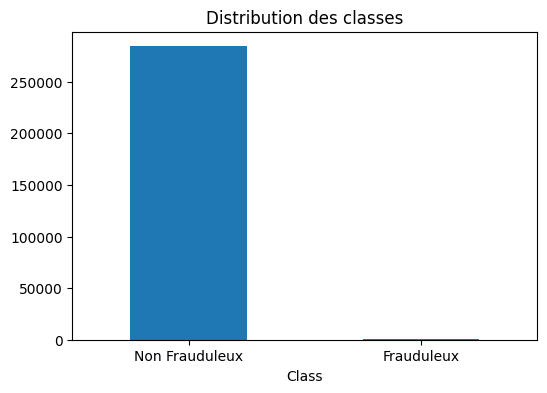

In [12]:
# bar chart de la distribution des classes
plt.figure(figsize=(6, 4))
df['Class'].value_counts().rename(index={0: 'Non Frauduleux', 1: 'Frauduleux'}).plot(kind='bar')
plt.title('Distribution des classes')
plt.xticks(rotation=0)

In [13]:
def show_correlation_matrix(df):
    plt.figure(figsize=(20, 20))
    sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
    plt.title('Matrice de corrélation')
    plt.show()

In [15]:
def get_top_correlations(df, target_col, top_n=10):
    correlations = df.corr()[target_col].abs().sort_values(ascending=False)
    return correlations[1:top_n+1]

In [16]:
get_top_correlations(df, 'Class', top_n=10)

V17    0.326481
V14    0.302544
V12    0.260595
V10    0.216884
V16    0.196539
V3     0.192962
V7     0.187257
V11    0.154876
V4     0.133448
V18    0.111485
Name: Class, dtype: float64

In [18]:
df["Amount"].describe()

count    284806.000000
mean         88.349756
std         250.120538
min           0.000000
25%           5.600000
50%          22.000000
75%          77.167500
max       25691.160000
Name: Amount, dtype: float64

In [19]:
df[df.Class == 1]["Amount"].describe()

count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

<Axes: >

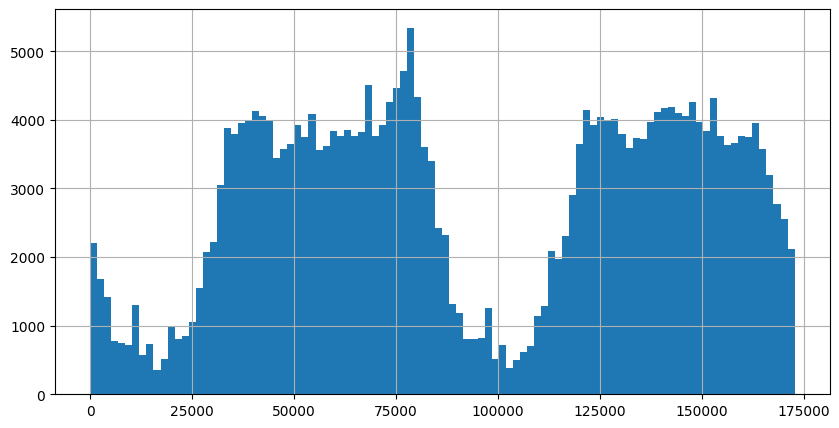

In [20]:
df["Time"].hist(bins=100, figsize=(10, 5))

In [21]:
df["Hours_since_first_transaction"] = df["Time"] / 3600
df["Hours"] = df["Hours_since_first_transaction"] % 24

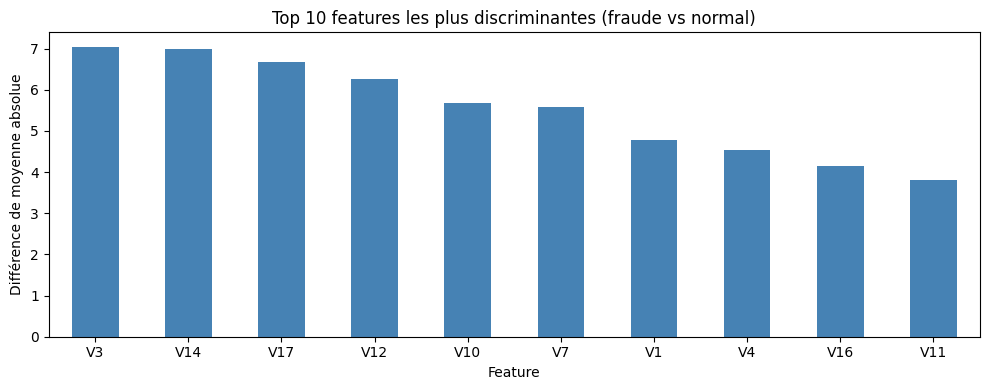

Top 10 :
V3     7.045443
V14    6.983785
V17    6.677370
V12    6.270232
V10    5.686711
V7     5.578374
V1     4.780211
V4     4.549890
V16    4.147110
V11    3.806750
dtype: float64


In [22]:
# Calcule la différence de moyenne entre fraudes et normal pour chaque V
feature_cols = [f'V{i}' for i in range(1, 29)]

diff = abs(df[df['Class']==1][feature_cols].mean() - 
           df[df['Class']==0][feature_cols].mean())

# Top 10 features les plus discriminantes
top_features = diff.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 4))
top_features.plot(kind='bar', color='steelblue')
plt.title('Top 10 features les plus discriminantes (fraude vs normal)')
plt.xlabel('Feature')
plt.ylabel('Différence de moyenne absolue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Top 10 :")
print(top_features)


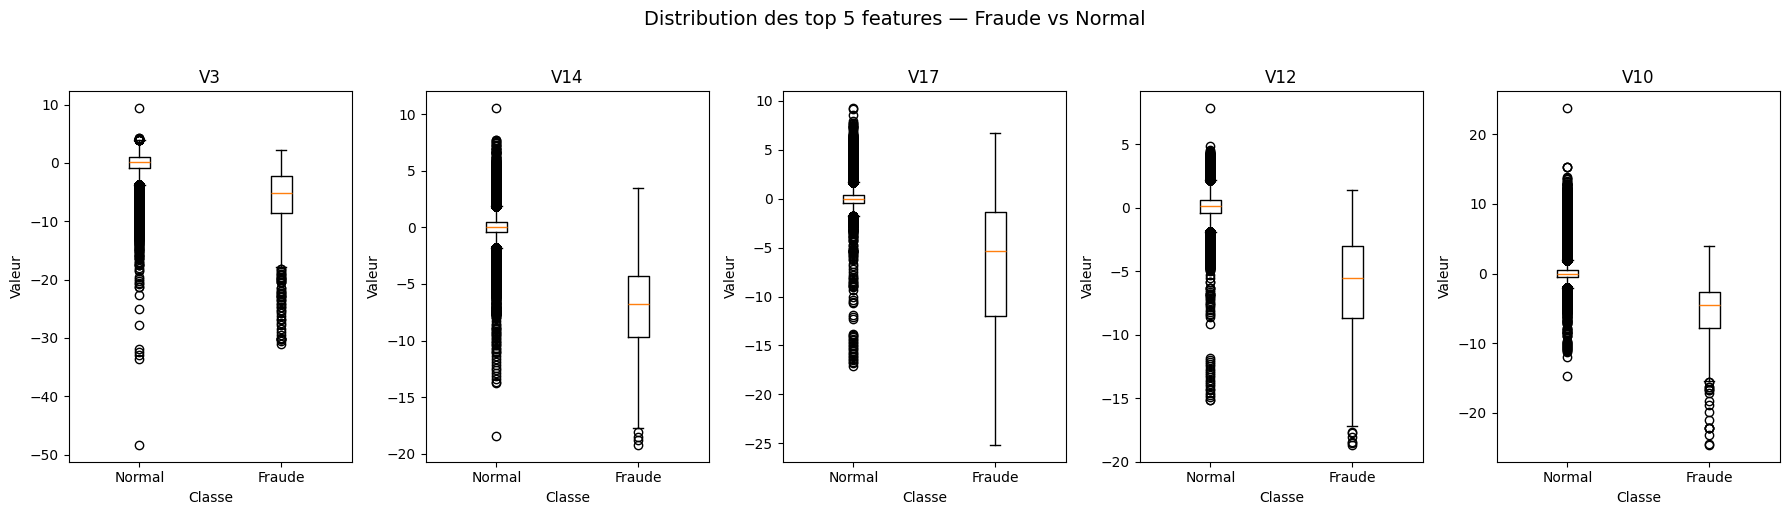

In [23]:
top5 = ['V3', 'V14', 'V17', 'V12', 'V10']

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for i, feature in enumerate(top5):
    fraud = df[df['Class']==1][feature]
    normal = df[df['Class']==0][feature]
    
    axes[i].boxplot([normal, fraud], labels=['Normal', 'Fraude'])
    axes[i].set_title(f'{feature}')
    axes[i].set_xlabel('Classe')
    axes[i].set_ylabel('Valeur')

plt.suptitle('Distribution des top 5 features — Fraude vs Normal', 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [24]:
def show_distributions(df, features):
    n = len(features)
    rows = (n + 1) // 2

    fig, axes = plt.subplots(rows, 2, figsize=(10,  10),squeeze=False)

    for i, feature in enumerate(features):
        row, col = i // 2, i % 2
        sns.kdeplot(df[df['Class']==0][feature], 
                    label='Normal', fill=True, ax=axes[row, col])
        sns.kdeplot(df[df['Class']==1][feature], 
                    label='Fraude', fill=True, ax=axes[row, col])
        axes[row, col].set_title(f'Distribution de {feature}')
        axes[row, col].set_xlabel(feature)
        axes[row, col].set_ylabel('Densité')
        axes[row, col].legend()
    # Cache le dernier subplot si nombre impair
    if n % 2 != 0:
        axes[-1, -1].set_visible(False)
    plt.tight_layout()
    plt.show()



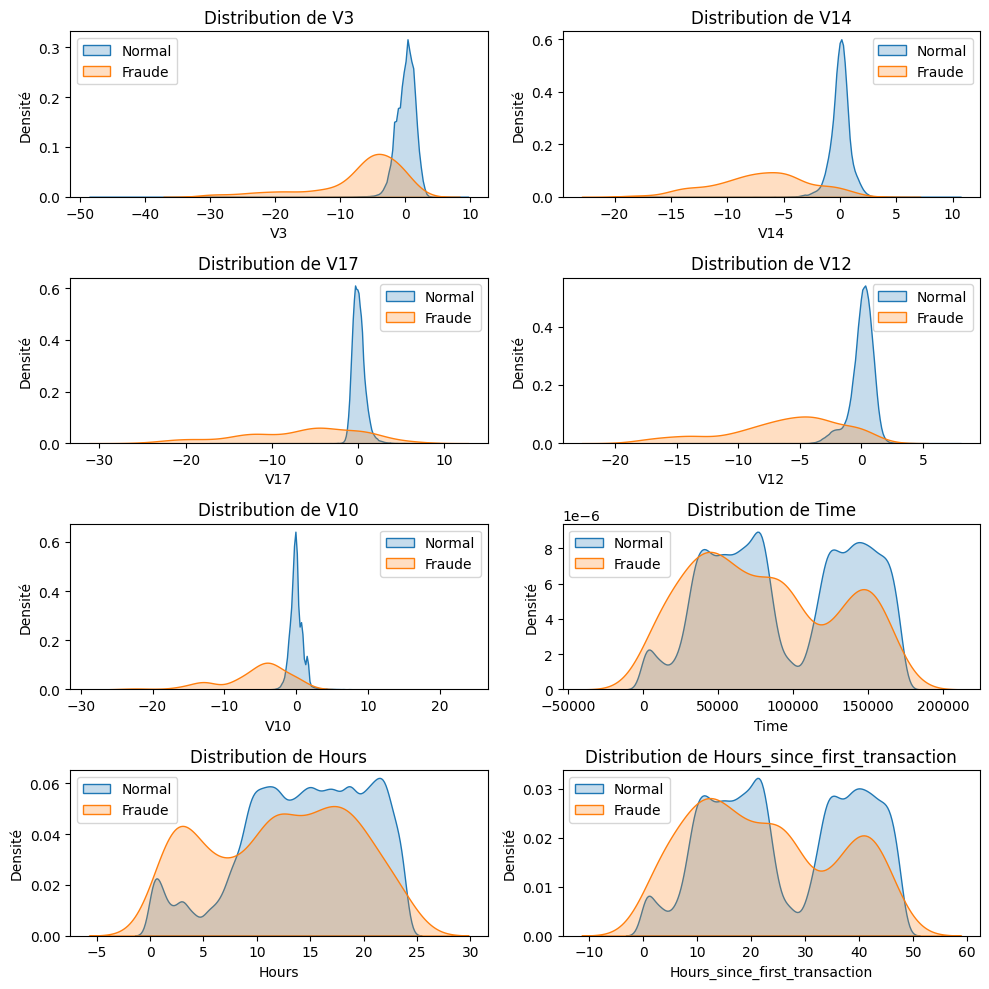

In [25]:
show_distributions(df, ['V3', 'V14', 'V17', 'V12', 'V10',"Time","Hours","Hours_since_first_transaction"])

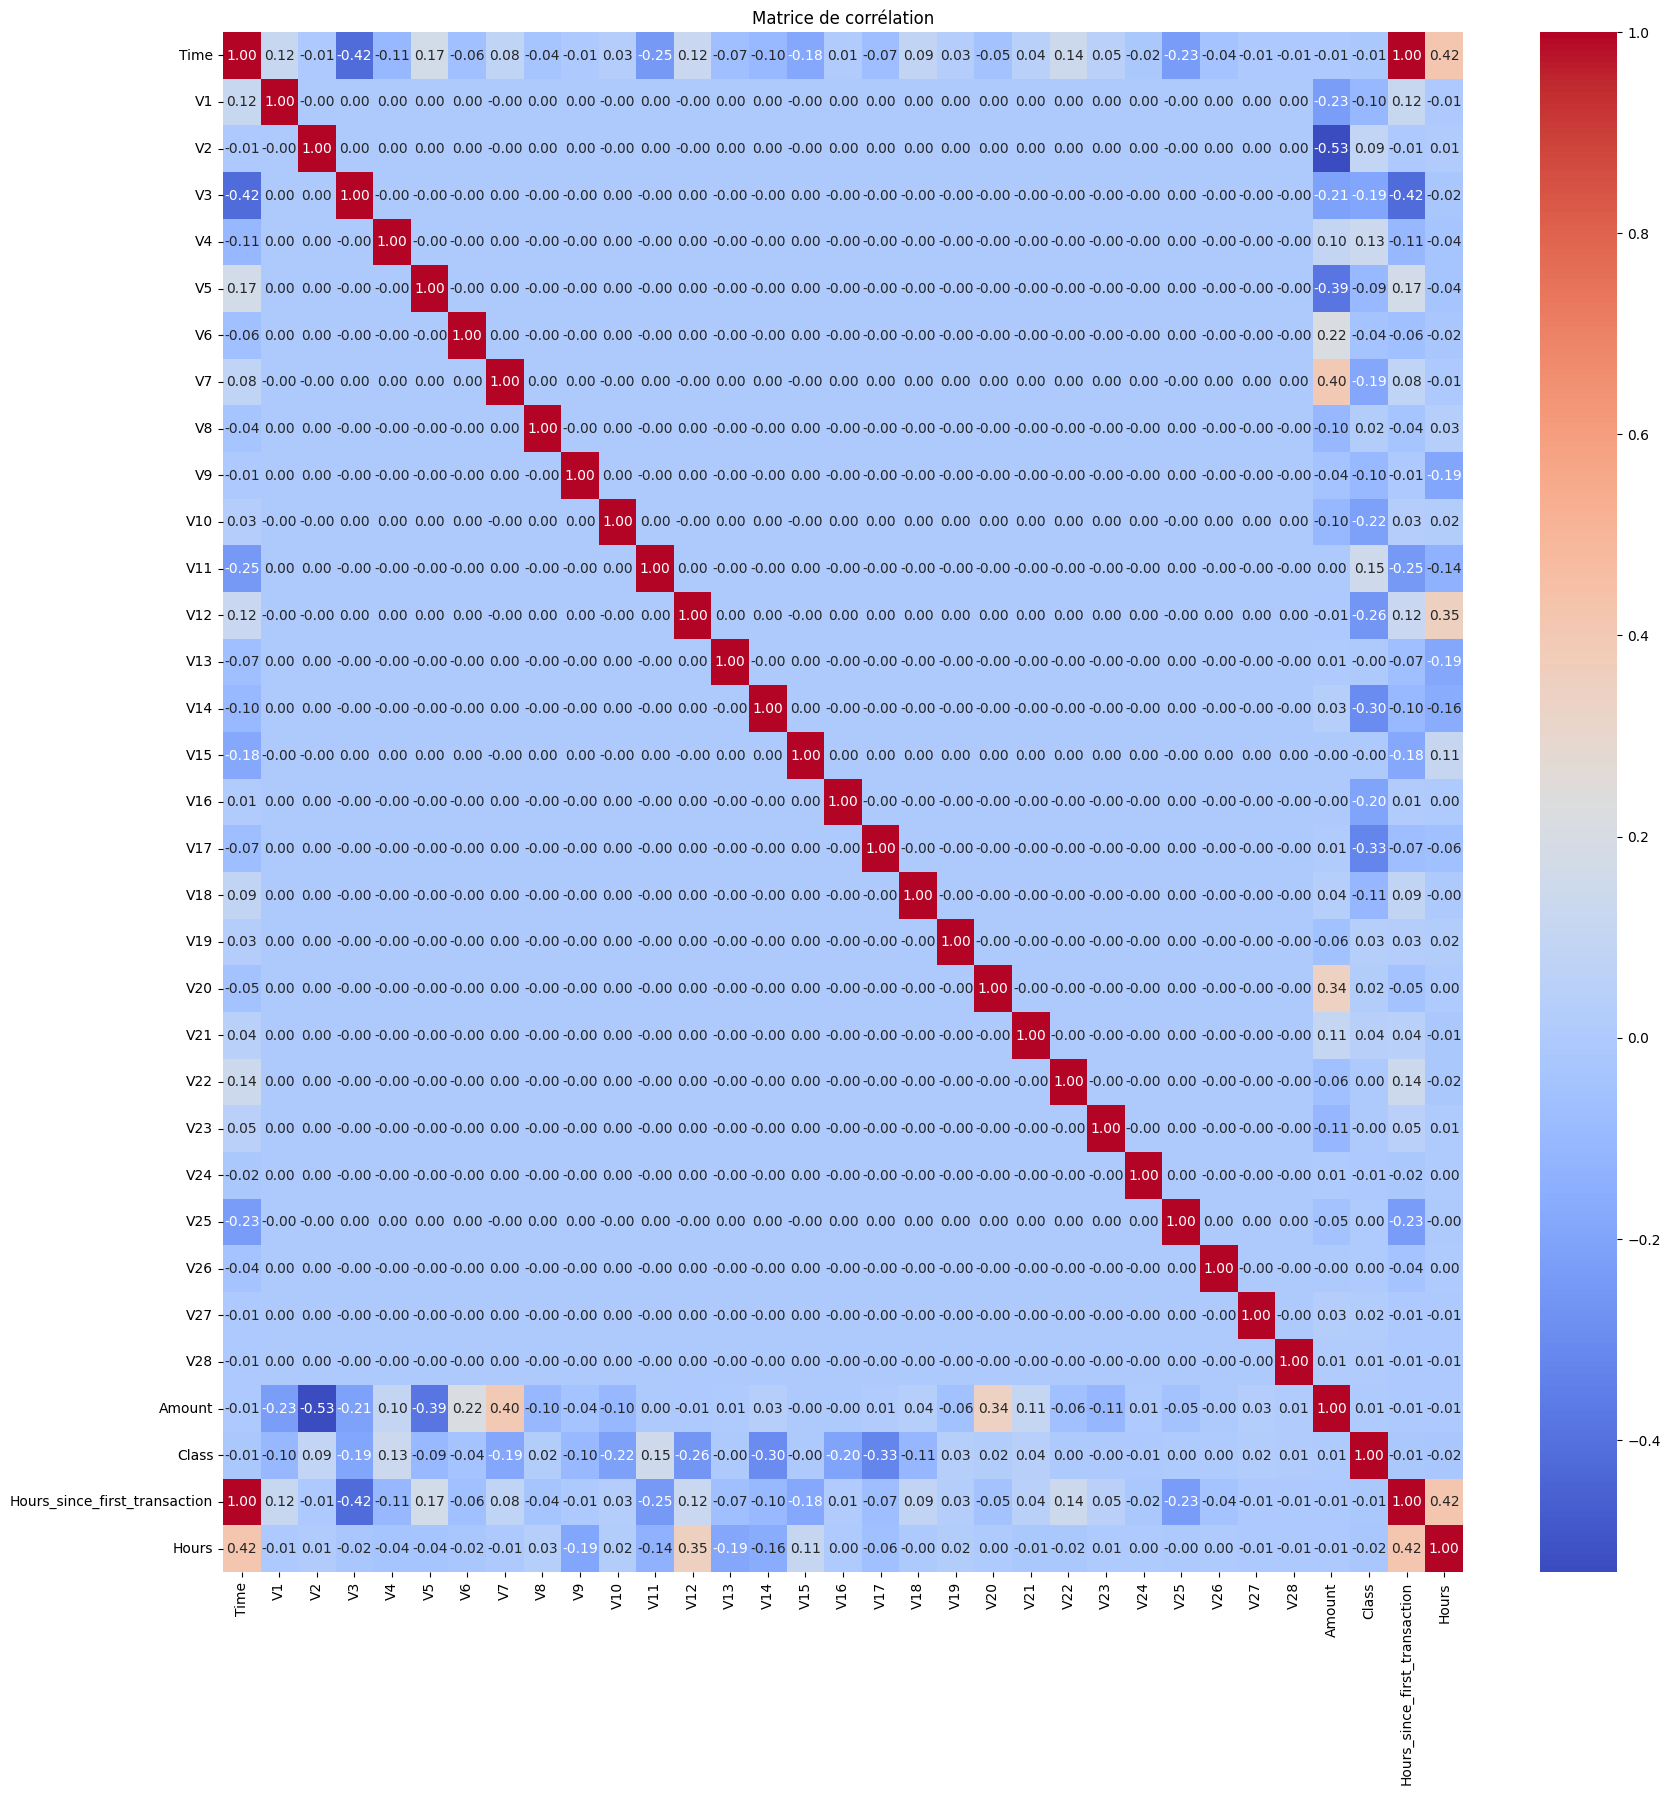

In [26]:
show_correlation_matrix(df)